# Module 4 — Supervised Learning: Regression

**Predicting a number.** Same pipeline as Module 2, same discipline as Module 3 — a new kind of label, and a new way to judge the answer.

**Dataset:** California housing, 1990 census — 20,640 neighbourhoods ("block groups"), nine facts about each, and the median house price.

**Three sessions, one table.** Every algorithm we meet adds one row to the same results table. By the end, the table *is* the lecture.

| | |
|---|---|
| **I · Tue Nov 3** | Judging a number · the data · OLS · ridge and lasso |
| **II · Thu Nov 5** | Tuning with cross-validation · one tree · random forest · the idea of boosting |
| **III · Tue Nov 10** | Gradient boosting and XGBoost · what matters · the punchline on another dataset |

### Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import seaborn as sns
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

REPO = "https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

---
## Part I — A number, and how to judge it

### 1 · Where we are

| | Module 3 | Module 4 |
|---|---|---|
| the label | a category: goal / no goal, default / repay | **a number**: a price, a fare, a wage |
| the model outputs | a probability, then a decision | **the number itself** |
| the mistake | wrong box in the confusion matrix | **a distance**: how far off, in dollars |
| what we judge | precision, recall, cost | **the size of the typical miss** |

Everything else — partition, preprocessing fit on train only, replicate on test, cross-validation — is Module 2, unchanged.

### Judging a number

Three numbers you will see everywhere. For a test set of $n$ houses with true prices $y_i$ and predictions $\hat y_i$:

| metric | formula | reads as |
|---|---|---|
| **MAE** — mean absolute error | $\frac{1}{n}\sum \lvert y_i - \hat y_i \rvert$ | *the typical miss, in dollars.* Robust to a few huge misses |
| **RMSE** — root mean squared error | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | *also in dollars,* but big misses are punished more. Always ≥ MAE |
| **R²** | $1 - \frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | *share of the variation explained.* Unit-free; 0 = predicting the mean, 1 = perfect |

**We will lead with MAE in dollars.** A lender, a buyer, an airline — nobody acts on an R². They act on "you'll be off by about $45,000."

One more: regression has no threshold. There is no decision to tune after the fact — the prediction *is* the output. The judgment moves upstream, into the features and the model.

### 2 · The data: California housing, 1990

One row = one census block group (a neighbourhood of ~1,500 people). The label is the **median house value** in that neighbourhood.

In [2]:
housing = pd.read_csv(f"{REPO}/california_housing.csv")
print(housing.shape)
housing.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


### Exploratory Data Analysis (A very brief version)

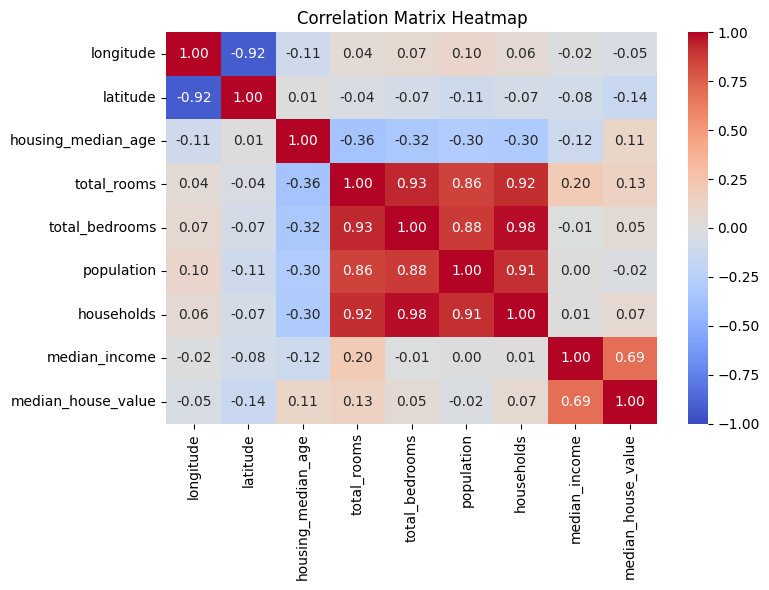

In [5]:


# Compute correlation matrix for numeric columns
corr = housing.select_dtypes("number").corr()

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
print(housing.dtypes.to_string(), "\n")
print("missing values:\n", housing.isna().sum()[housing.isna().sum() > 0].to_string(), "\n")
print(housing.ocean_proximity.value_counts().to_string(), "\n")
print("skewness:\n", housing.select_dtypes("number").skew().round(2).to_string(), "\n")
print(f"price capped: {(housing.median_house_value >= 500_000).sum()} rows at $500,001")

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object 

missing values:
 total_bedrooms    207 

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5 

skewness:
 longitude            -0.300
latitude              0.470
housing_median_age    0.060
total_rooms           4.150
total_bedrooms        3.460
population            4.940
households            3.410
median_income         1.650
median_house_value    0.980 

price capped: 992 rows at $500,001


### What a careful look finds

- **`total_bedrooms` is missing on 207 rows** (1%). Small — but a linear model will refuse to fit with a single missing value. Imputation, fit on train only, is step one.
- **`ocean_proximity` is text** with five categories. One of them, ISLAND, has five rows. We need to encode it — and remember that a category the training data never saw can still turn up in the test set.
- **Four count columns are heavily skewed** (`total_rooms`, `population`, … skew 3–5). They are totals for a neighbourhood, not per-house figures. Ratios (rooms per household) are what economists would reach for.
- **The target is capped at $500,001** — 992 neighbourhoods sit exactly there. The data cannot tell a $500k neighbourhood from a $2M one. Keep it in mind when the model "misses" at the top.
- **It's 1990.** The prices are 1990 prices.

None of this is unusual. It is what a clean-looking numeric file looks like up close.

### The target: should we predict price, or log price?

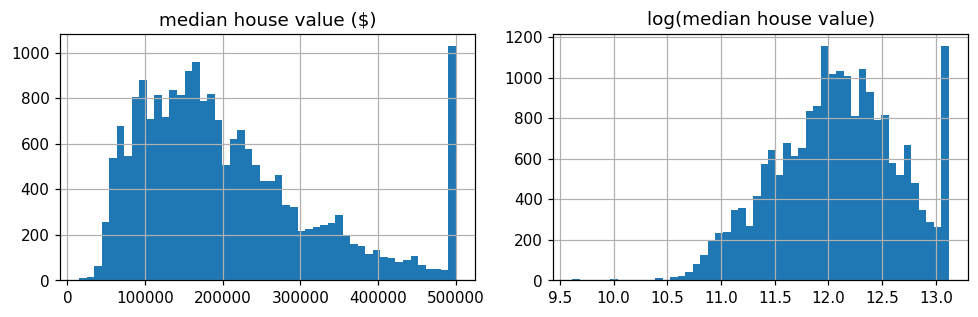

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
housing.median_house_value.hist(bins=50, ax=ax[0]); ax[0].set_title("median house value ($)")
np.log(housing.median_house_value).hist(bins=50, ax=ax[1]); ax[1].set_title("log(median house value)")
plt.tight_layout(); plt.show()

Prices are right-skewed with a wall at the cap. A linear model fit to raw dollars spends its effort on the expensive tail; fit to **log price** it works in *percent* terms, and a 10% miss costs the same whether the house is cheap or dear. We will try both — and convert back to dollars before we judge, because MAE in log units means nothing to anyone.

### 3 · Partition

80 / 20, before we learn anything. Validation inside the 80 comes from cross-validation when we need it.

In [ ]:
X = housing.drop(columns="median_house_value")
y = housing.median_house_value
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train /", len(X_test), "test   | median price in train:", f"${y_train.median():,.0f}")

16512 train / 4128 test   | median price in train: $179,850


### 4 · Preprocessing, built once

A `ColumnTransformer`: numeric columns get median imputation; the text column gets one-hot encoding. Fit on the training split, replicated on everything else — automatically, because it lives inside the pipeline.

We also add three **ratio features** an economist would want: rooms per household, bedrooms per room, people per household. Totals describe the neighbourhood's size; ratios describe its houses.

In [ ]:
def add_ratios(d):
    d = d.copy()
    d["rooms_per_household"]  = d.total_rooms / d.households
    d["bedrooms_per_room"]    = d.total_bedrooms / d.total_rooms
    d["people_per_household"] = d.population / d.households
    return d

NUM = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
       "population", "households", "median_income",
       "rooms_per_household", "bedrooms_per_room", "people_per_household"]
CAT = ["ocean_proximity"]

preprocess = make_pipeline(
    FunctionTransformer(add_ratios),
    ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ]),
)
Xt = preprocess.fit_transform(X_train)
print("model-ready matrix:", Xt.shape, "| any NaN left?", np.isnan(Xt).any())

model-ready matrix: (16512, 16) | any NaN left? False


### The helper: fit, judge, add a row

Every model from here on goes through this one function. `log_target=True` wraps the model so it trains on log price and predicts back in dollars.

In [ ]:
results = pd.DataFrame(columns=["target", "test MAE ($)", "test RMSE ($)", "test R²", "train R²"])

def report(name, model, log_target=True, prep=None):
    pipe = make_pipeline(prep if prep is not None else preprocess, model)
    if log_target:
        pipe = TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    pipe.fit(X_train, y_train)
    p_test, p_train = pipe.predict(X_test), pipe.predict(X_train)
    results.loc[name] = ["log price" if log_target else "price",
                         mean_absolute_error(y_test, p_test),
                         np.sqrt(mean_squared_error(y_test, p_test)),
                         r2_score(y_test, p_test), r2_score(y_train, p_train)]
    return pipe

def show(table=None):
    out = (results if table is None else table).copy()
    for c in out.columns:
        if "$" in c: out[c] = out[c].map("{:,.0f}".format)
        elif "R²" in c: out[c] = out[c].map("{:.3f}".format)
    return out

### 5 · Ordinary least squares — the model you already know

Row one. Twice: on raw price and on log price.

In [ ]:
ols_raw = report("OLS, raw price", LinearRegression(), log_target=False)
ols_log = report("OLS, log price", LinearRegression())
show()

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414


### Reading the first rows

- The typical miss is about **$50,000 on a $180,000 house** — a 28% error. Serviceable, not impressive.
- **Log price made it worse.** Surprising? Think about the shape: log price against a *raw* population count says that going from 300 people to 600 moves price by the same amount as going from 30,000 to 30,300. That is the wrong shape, and a few extreme neighbourhoods produce wild predictions once we exponentiate.
- Train R² and test R² are close: OLS with 16 features and 16,000 rows is not overfitting. The problem is the *shape*.

### Adjusting skewness: log the features too

The four count columns and the ratios are skewed by a factor of 3–5. Logging them *and* the target gives the economist's favourite model — **log-log**, where every coefficient is an elasticity: a 1% change in income moves price by β%. Same shape on both sides of the equation.

From here on, every model uses this preprocessing. (Trees won't care — a log is a monotone relabelling of the cut points — but it costs nothing.)

In [ ]:
SKEWED = ["total_rooms", "total_bedrooms", "population", "households", "median_income",
          "rooms_per_household", "people_per_household"]

def log_skewed(d):
    d = d.copy()
    for c in SKEWED:
        d[c] = np.log1p(d[c])
    return d

preprocess = make_pipeline(
    FunctionTransformer(add_ratios),
    FunctionTransformer(log_skewed),
    ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ]),
)
ols = report("OLS, log-log", LinearRegression())
show()

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673


### The shape was the problem

Log on both sides: the typical miss drops from about $50,000 to about **$46,000**, and R² is back where it was. The "adjust skewness" step is not a ritual — it is choosing a functional form, and a linear model lives or dies by it.

### 6 · More features, and the problem of too many

OLS is a straight line in every feature. One way to bend it: **polynomial features** — every square and every pairwise product. Eleven numeric columns at degree 2 become 81 columns.

That is fine with 16,000 rows. It is *not* fine with 300. Let's see what happens when the rows run out.

In [ ]:
poly_prep = make_pipeline(
    FunctionTransformer(add_ratios),
    FunctionTransformer(log_skewed),
    ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                             PolynomialFeatures(degree=2, include_bias=False)), NUM),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]),
)
small = X_train.sample(300, random_state=1).index   # pretend we only had 300 neighbourhoods

for name, model in [("OLS", LinearRegression()), ("ridge", Ridge(alpha=10))]:
    pipe = make_pipeline(poly_prep, model).fit(X_train.loc[small], y_train.loc[small])   # raw price, to keep the damage finite
    print(f"{name:6s} degree-2 polynomial, 300 rows:  "
          f"features = {pipe[:-1].transform(X_train.loc[small]).shape[1]}  "
          f"train R² = {r2_score(y_train.loc[small], pipe.predict(X_train.loc[small])):.3f}  "
          f"test MAE = ${mean_absolute_error(y_test, pipe.predict(X_test)):,.0f}")

OLS    degree-2 polynomial, 300 rows:  features = 81  train R² = 0.814  test MAE = $798,043
ridge  degree-2 polynomial, 300 rows:  features = 81  train R² = 0.767  test MAE = $46,779


### What just happened

With 81 features and 300 rows, OLS fits the training data well — and its test error is **sixteen times worse** than the OLS we fit on all 16,000 rows. Module 2's overfitting, back in a new costume: not a wiggly curve this time, but a plane with too many knobs and too few rows to pin them down.

Ridge, with the *same* features and the *same* 300 rows, gives up a little training fit and lands within $1,000 of the full-data OLS. That is what a penalty buys — and it buys the most exactly when the data runs out.

### 7 · Ridge and lasso — a penalty on the coefficients

OLS minimises the squared error. Ridge and lasso minimise the squared error **plus a price for large coefficients:**

$$\text{ridge:}\quad \sum_i (y_i - \mathbf{x}_i\boldsymbol\beta)^2 \;+\; \lambda \sum_j \beta_j^2
\qquad\qquad
\text{lasso:}\quad \sum_i (y_i - \mathbf{x}_i\boldsymbol\beta)^2 \;+\; \lambda \sum_j \lvert\beta_j\rvert$$

- $\lambda = 0$ is OLS. Larger $\lambda$ shrinks every coefficient toward zero.
- **Ridge shrinks.** Coefficients get small, never exactly zero.
- **Lasso selects.** The absolute-value penalty pushes weak coefficients *exactly* to zero — the model drops features by itself.
- **Elastic net** mixes the two penalties. One slider, both behaviours.

The economist's reading: a penalty is a prior that effects are small. With few rows and many features, that prior is worth more than the data's own opinion.

### Scale first, or the penalty is unfair

The penalty charges every coefficient the same price. But a coefficient's size depends on its feature's units: `median_income` runs 0.5–15, `population` runs into the thousands. Unscaled, the penalty crushes whichever feature happens to have big numbers.

**Standardise every numeric feature before penalising.** Trees won't care about this. Penalised linear models care about nothing else.

In [ ]:
scaled_prep = make_pipeline(
    FunctionTransformer(add_ratios),
    FunctionTransformer(log_skewed),
    ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]),
)
ridge = report("ridge (λ = 1)",  Ridge(alpha=1.0),  prep=scaled_prep)
lasso = report("lasso (λ = 0.001)", Lasso(alpha=0.001), prep=scaled_prep)
show()

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675


### Lasso as a selector

Which features survived? Read the coefficients (on standardised features, so they are comparable).

4 of 16 coefficients set exactly to zero: ['total_bedrooms', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


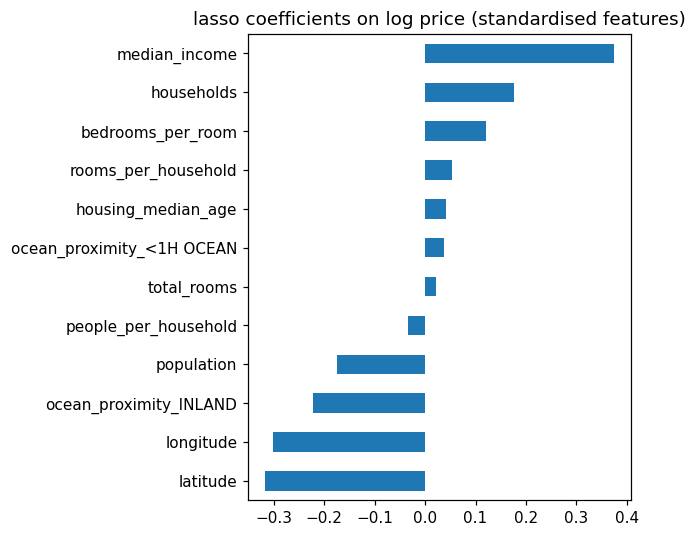

In [ ]:
feat_names = NUM + list(lasso.regressor_[0][-1].named_transformers_["cat"].get_feature_names_out(CAT))
coef = pd.Series(lasso.regressor_[-1].coef_, index=feat_names).sort_values()
print(f"{(coef == 0).sum()} of {len(coef)} coefficients set exactly to zero:", list(coef[coef == 0].index))
coef[coef != 0].plot.barh(figsize=(6, 5), title="lasso coefficients on log price (standardised features)")
plt.tight_layout(); plt.show()

### Where Part I leaves us

Three linear models, three nearly identical rows. The penalty did its job in the 300-row world; with 16,000 rows the line simply isn't bent in the right places. Every linear row misses by about **$46,000**.

**Thursday:** a model with no line in it at all.

---
## Part II — Trees, and why many beat one

### 8 · Tuning λ properly: cross-validation

Tuesday we picked λ by hand. The honest way is Module 2's cross-validation: try a grid of λ, score each by 5-fold CV *inside the training split*, keep the best. `LassoCV` does exactly that.

In [ ]:
lasso_cv = report("lasso (λ by CV)", LassoCV(cv=5, random_state=0), prep=scaled_prep)
print("λ chosen by cross-validation:", round(lasso_cv.regressor_[-1].alpha_, 5))
show()

λ chosen by cross-validation: 0.00039


,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675
lasso (λ by CV),log price,"45,744","67,472",0.653,0.679


### 9 · One tree

A regression tree asks a sequence of yes/no questions about the features and predicts the **average price of the training houses that landed in the same leaf**. No line, no coefficients, no units — a tree never needs scaling, and it finds interactions by itself.

*(deck slides 60–69: how a split is chosen — try every feature and every cut point, keep the one that reduces squared error most)*

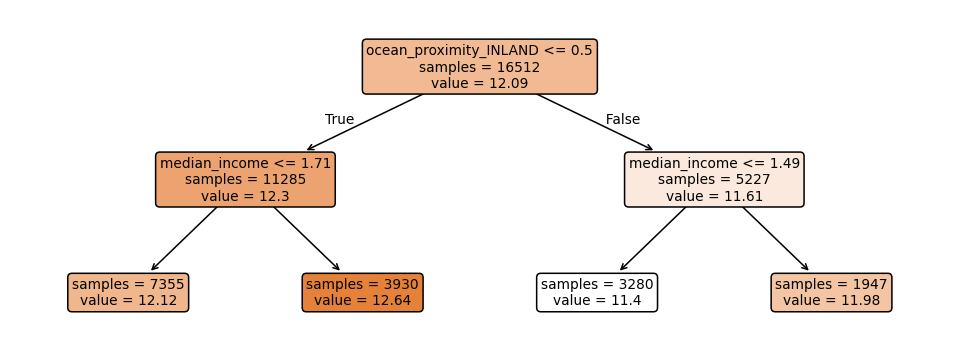

In [ ]:
tree2 = report("tree, depth 2", DecisionTreeRegressor(max_depth=2, random_state=0))
fig, ax = plt.subplots(figsize=(11, 4))
plot_tree(tree2.regressor_[-1], feature_names=feat_names, filled=True, rounded=True, fontsize=9, ax=ax,
          precision=2, impurity=False)
plt.show()

### Read the tree

The first question the tree asks is about **income**. The second, on each side, is about income again or about **location**. Two questions, four leaves, four predicted (log) prices. That is a model.

Depth 2 is a toy. Let the tree grow until every leaf is pure.

In [ ]:
tree_full = report("tree, full depth", DecisionTreeRegressor(random_state=0))
show()

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675
lasso (λ by CV),log price,"45,744","67,472",0.653,0.679
"tree, depth 2",log price,"62,189","87,380",0.417,0.433
"tree, full depth",log price,"43,972","69,794",0.628,1.000


### The tree memorised the training set

Train R² = 1.000. Every training house sits alone in its own leaf, predicted perfectly. Test MAE: **worse than OLS.** The full-depth tree is Module 2's perfect fit, again.

Depth is a dial. Turn it.

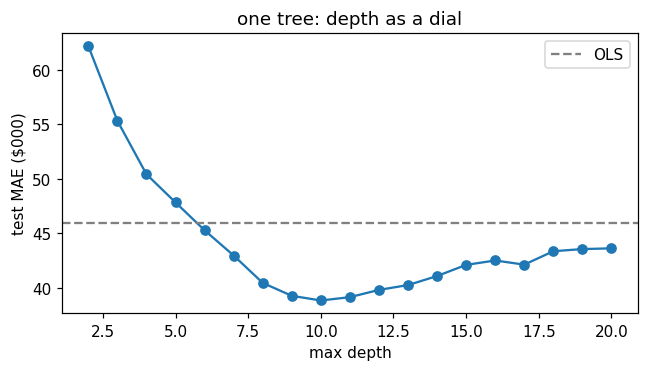

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675
lasso (λ by CV),log price,"45,744","67,472",0.653,0.679
"tree, depth 2",log price,"62,189","87,380",0.417,0.433
"tree, full depth",log price,"43,972","69,794",0.628,1.000
"tree, depth 10",log price,"38,839","60,072",0.725,0.839


In [ ]:
depths = range(2, 21)
mae = [mean_absolute_error(y_test, TransformedTargetRegressor(
           regressor=make_pipeline(preprocess, DecisionTreeRegressor(max_depth=d, random_state=0)),
           func=np.log, inverse_func=np.exp).fit(X_train, y_train).predict(X_test)) for d in depths]
best_d = list(depths)[int(np.argmin(mae))]
plt.figure(figsize=(6, 3.5)); plt.plot(depths, np.array(mae) / 1000, marker="o")
plt.axhline(results.loc["OLS, log-log", "test MAE ($)"] / 1000, ls="--", color="gray", label="OLS")
plt.xlabel("max depth"); plt.ylabel("test MAE ($000)"); plt.title("one tree: depth as a dial"); plt.legend()
plt.tight_layout(); plt.show()
tree_best = report(f"tree, depth {best_d}", DecisionTreeRegressor(max_depth=best_d, random_state=0))
show()

### A tuned tree beats the line

At its best depth a single tree misses by about $39,000 — 15% less than the best linear model, with no feature engineering at all. But look at the curve: the sweet spot is narrow, and a tree that deep is a brittle object — move a few training rows and the splits change.

The fix is not a better tree. It is **many trees.**

### 10 · Random forest — many overfit trees, averaged

Two ingredients, both from the deck (slides 71–86):

1. **Bootstrap.** Draw the training rows *with replacement* — a new, slightly different dataset each time. Grow a full-depth tree on each.
2. **Random features.** At every split, let the tree choose from a random subset of the features, so the trees don't all ask the same first question.

Each tree overfits its own sample. Their errors are different, so when you **average** a few hundred of them, the overfitting averages away and the signal stays. Bagging = bootstrap + aggregate.

In [ ]:
forest = report("random forest (200 trees)", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0))
show()

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675
lasso (λ by CV),log price,"45,744","67,472",0.653,0.679
"tree, depth 2",log price,"62,189","87,380",0.417,0.433
"tree, full depth",log price,"43,972","69,794",0.628,1.000
"tree, depth 10",log price,"38,839","60,072",0.725,0.839
random forest (200 trees),log price,"31,151","49,983",0.809,0.969


### The table changes character

One line of code and the typical miss drops from about $46,000 to about **$31,000** — a third less error than every linear model, with no scaling, no tuning, and nothing the log-log step did mattering to it.

Train R² is high again — the forest still fits training data very closely — but this time the test error says it generalises. Overfitting that averages away is not overfitting.

### 11 · Boosting — the idea

A forest grows its trees *in parallel*, each ignorant of the others. Boosting grows them *in sequence*, each one correcting what the previous ones got wrong:

1. Start with a trivial prediction — the average price.
2. Compute the **residuals** — what's left unexplained.
3. Fit a *small* tree to the residuals.
4. Add a *fraction* of that tree's prediction to the running total (the fraction is the **learning rate**).
5. Repeat: new residuals, new small tree, small step. Stop when adding trees stops helping.

*(deck slides 87–97: the worked example — Tuesday we walk through the numbers)*

Small steps toward the right direction, hundreds of times. That is gradient boosting.

---
## Part III — Boosting, and what matters

### 12 · Gradient boosting, fitted

In [ ]:
gbr = report("gradient boosting (sklearn)", GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=0))
show()

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675
lasso (λ by CV),log price,"45,744","67,472",0.653,0.679
"tree, depth 2",log price,"62,189","87,380",0.417,0.433
"tree, full depth",log price,"43,972","69,794",0.628,1.000
"tree, depth 10",log price,"38,839","60,072",0.725,0.839
random forest (200 trees),log price,"31,151","49,983",0.809,0.969


### Watch it learn: test error against the number of trees

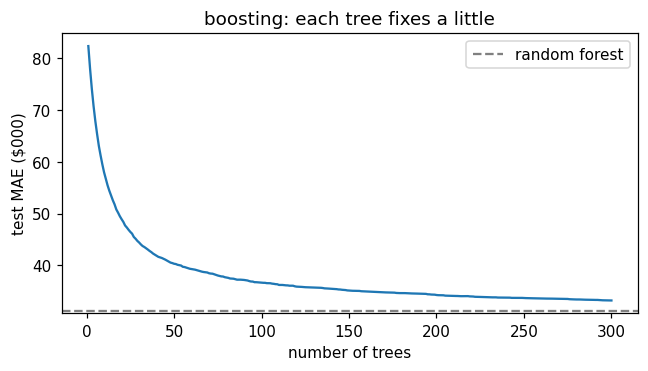

In [ ]:
inner = gbr.regressor_[-1]
Xte_t = gbr.regressor_[:-1].transform(X_test)
staged = [mean_absolute_error(y_test, np.exp(p)) for p in inner.staged_predict(Xte_t)]
plt.figure(figsize=(6, 3.5)); plt.plot(range(1, len(staged) + 1), np.array(staged) / 1000)
plt.axhline(results.loc["random forest (200 trees)", "test MAE ($)"] / 1000, ls="--", color="gray", label="random forest")
plt.xlabel("number of trees"); plt.ylabel("test MAE ($000)"); plt.title("boosting: each tree fixes a little"); plt.legend()
plt.tight_layout(); plt.show()

### XGBoost — the same idea, engineered

XGBoost ("extreme gradient boosting") is gradient boosting with a regularised objective, a smarter way of choosing splits, native handling of missing values, and a fast, parallel implementation. It won most tabular-data competitions for a decade and is still the default choice for structured data in industry. Scikit-learn's `HistGradientBoostingRegressor` is the same family.

Same interface: fit, predict, one row.

In [ ]:
from xgboost import XGBRegressor
xgb = report("XGBoost", XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, random_state=0))
hgb = report("hist gradient boosting (sklearn)", HistGradientBoostingRegressor(random_state=0))
show()

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675
lasso (λ by CV),log price,"45,744","67,472",0.653,0.679
"tree, depth 2",log price,"62,189","87,380",0.417,0.433
"tree, full depth",log price,"43,972","69,794",0.628,1.000
"tree, depth 10",log price,"38,839","60,072",0.725,0.839
random forest (200 trees),log price,"31,151","49,983",0.809,0.969


### 13 · The whole table

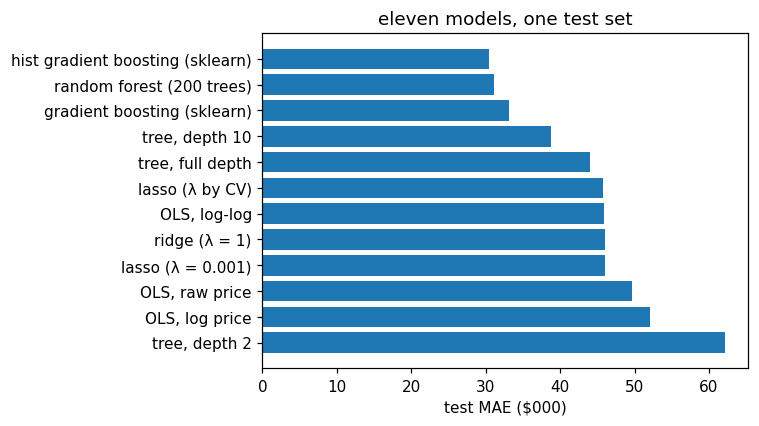

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675
lasso (λ by CV),log price,"45,744","67,472",0.653,0.679
"tree, depth 2",log price,"62,189","87,380",0.417,0.433
"tree, full depth",log price,"43,972","69,794",0.628,1.000
"tree, depth 10",log price,"38,839","60,072",0.725,0.839
random forest (200 trees),log price,"31,151","49,983",0.809,0.969


In [ ]:
order = results.sort_values("test MAE ($)", ascending=False)
plt.figure(figsize=(7, 4)); plt.barh(order.index, order["test MAE ($)"] / 1000)
plt.xlabel("test MAE ($000)"); plt.title("eleven models, one test set"); plt.tight_layout(); plt.show()
show()

### Read the table

- **Every linear model misses by about $46k. Every ensemble misses by $30–33k.** The gap is not tuning — the forest and the boosters ran on default settings.
- The ensembles never saw a scaled feature, never needed the log target, and would have run with the missing values left in. **Trees don't care about the preprocessing that linear models cannot live without.**
- A single tree is worse than OLS; two hundred of them are far better. The power is in the *ensemble*, not the tree.
- Boosting and bagging land in the same place here. On other data one wins clearly; try both.

### 14 · What matters? Opening the box

A coefficient tells you what a linear model thinks. An ensemble has no coefficients. Two tools that work for *any* model:

- **Permutation importance:** shuffle one feature's column in the test set and see how much the error rises. If the model wasn't using the feature, nothing happens.
- **Partial dependence:** hold everything else fixed, sweep one feature across its range, and plot the model's average prediction. The *shape* of the relationship the model learned.

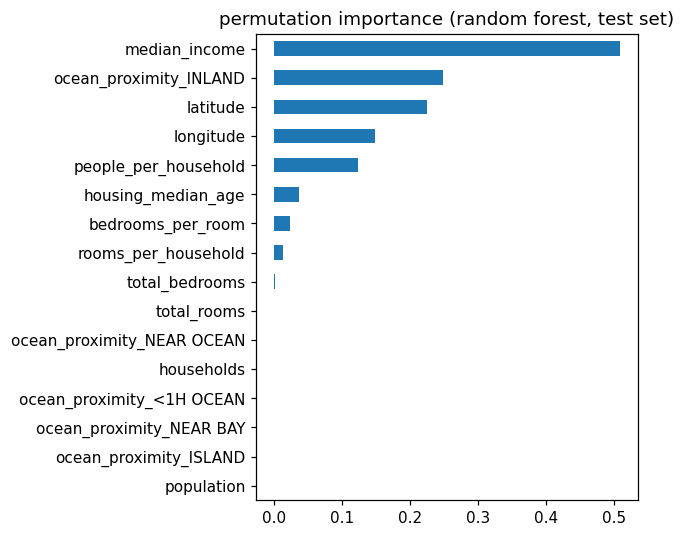

In [ ]:
model = forest
Xte_t = model.regressor_[:-1].transform(X_test)
pi = permutation_importance(model.regressor_[-1], Xte_t, np.log(y_test), n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=feat_names).sort_values()
imp.plot.barh(figsize=(6, 5), title="permutation importance (random forest, test set)")
plt.tight_layout(); plt.show()

### Why the line lost: location

Income is the strongest feature — the line had that. The next two are **latitude and longitude**, and that is the point: price depends on *where* you are, which is a joint function of two coordinates — a map. A line can only add a north–south slope to an east–west slope. A tree can carve the map into regions.

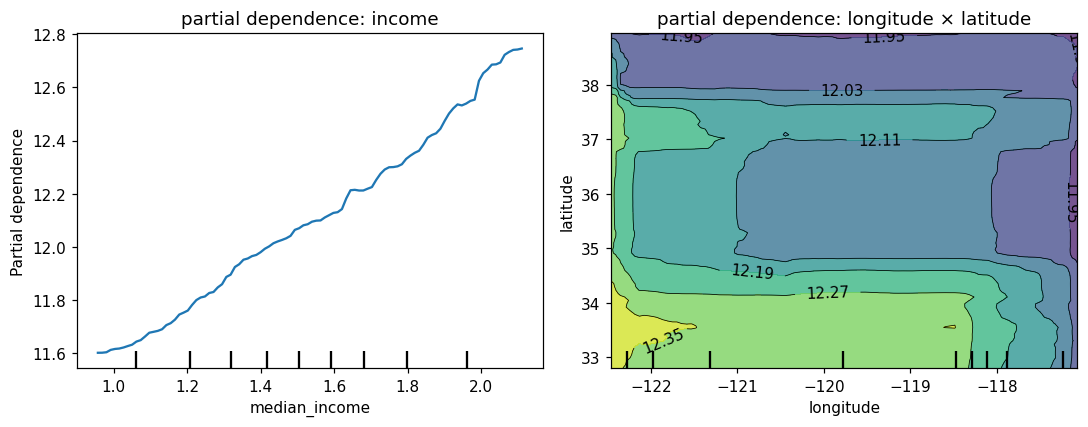

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
PartialDependenceDisplay.from_estimator(model.regressor_[-1], Xte_t, features=[feat_names.index("median_income")],
                                        feature_names=feat_names, ax=ax[0])
ax[0].set_title("partial dependence: income")
PartialDependenceDisplay.from_estimator(model.regressor_[-1], Xte_t,
                                        features=[(feat_names.index("longitude"), feat_names.index("latitude"))],
                                        feature_names=feat_names, ax=ax[1])
ax[1].set_title("partial dependence: longitude × latitude")
plt.tight_layout(); plt.show()

### 15 · The punchline — another dataset, the opposite answer

Ames, Iowa: 1,460 house sales, 80 raw characteristics. In an earlier version of this course we spent two full sessions preprocessing it — imputing, encoding ordinal quality scales by hand, logging the skewed columns, one-hot encoding the rest. 215 model-ready features.

Fit the same models to *that*.

In [ ]:
Xa_train = pd.read_csv(f"{REPO}/X_train_ready.csv", index_col=0).drop(columns="Id")
Xa_test  = pd.read_csv(f"{REPO}/X_test_ready.csv",  index_col=0).drop(columns="Id")
ya_train = pd.read_csv(f"{REPO}/y_train.csv", index_col=0).squeeze()
ya_test  = pd.read_csv(f"{REPO}/y_test.csv",  index_col=0).squeeze()
print(Xa_train.shape, Xa_test.shape, "| median price", f"${ya_train.median():,.0f}")

ames = pd.DataFrame(columns=["test MAE ($)", "test R²"])
for name, m in [("OLS", LinearRegression()),
                ("lasso (λ by CV)", make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=5000, random_state=0))),
                ("random forest (200 trees)", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)),
                ("hist gradient boosting", HistGradientBoostingRegressor(random_state=0))]:
    m.fit(Xa_train, np.log(ya_train)); p = np.exp(m.predict(Xa_test))
    ames.loc[name] = [mean_absolute_error(ya_test, p), r2_score(ya_test, p)]
show(ames)

(1168, 215) (292, 215) | median price $165,000


,test MAE ($),test R²
OLS,"14,887",0.929
lasso (λ by CV),"14,929",0.910
random forest (200 trees),"17,391",0.887
hist gradient boosting,"16,198",0.894


### Features beat algorithms — when you do the work

On Ames, **plain OLS beats the forest and the booster.** Same models, opposite verdict.

The difference is not the algorithm. It is 215 features that two sessions of human judgment built: *which* quality scales are ordinal, *which* columns to log, *what* a missing garage year means. Once the features carry the structure, a line is enough — and a line is faster, more stable, and you can read its coefficients.

- **Do nothing to the features → ensembles win big** (California: a third less error).
- **Do the work → the line catches up or wins** (Ames).

Which one you should do depends on what the prediction is for, how much time you have, and whether anyone needs to explain the model afterwards. That is a judgment, and it's yours.

### What to take away

1. **Judge a number in its own units.** MAE in dollars first; R² for comparison across datasets.
2. **Linear models need the preprocessing; trees don't.** Impute, encode, log, scale — for the line. The forest ran on the raw columns.
3. **A penalty is a prior that effects are small.** Ridge shrinks, lasso selects, and the penalty must be tuned by cross-validation on scaled features.
4. **One tree memorises. Many trees generalise.** Forests average; boosting corrects. Both beat the line by a third here with no tuning at all.
5. **Open the box with permutation importance and partial dependence.** They work for any model — and they told us *why* the line lost.
6. **Features versus algorithms is a trade-off, not a verdict.** Know which side of it your problem is on.

*Project 3: your turn, on a dataset where you will have to decide.*

---
## Appendix — tuning an ensemble (not covered in class)

Forests and boosters have knobs: number of trees, depth, learning rate, subsample fraction. `RandomizedSearchCV` tries random combinations, scores each by cross-validation on the training split, and keeps the best. It is the deck's "Part 3: cross-validation and grid search" applied to a forest. Expensive, and usually worth a few percent — never the difference between $45k and $30k.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
search = RandomizedSearchCV(
    RandomForestRegressor(random_state=0, n_jobs=-1),
    {"n_estimators": [100, 200, 400], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 2, 5], "max_features": [0.5, 0.8, 1.0]},
    n_iter=8, cv=3, scoring="neg_mean_absolute_error", random_state=0, n_jobs=-1)
Xtr_t = preprocess.fit_transform(X_train)
search.fit(Xtr_t, np.log(y_train))
print("best settings:", search.best_params_)
tuned = report("random forest (tuned)", RandomForestRegressor(random_state=0, n_jobs=-1, **search.best_params_))
show()

best settings: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20}


,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,645","69,127",0.635,0.658
"OLS, log price",log price,"52,060","90,690",0.372,0.414
"OLS, log-log",log price,"45,938","68,647",0.640,0.673
ridge (λ = 1),log price,"46,006","68,571",0.641,0.678
lasso (λ = 0.001),log price,"46,027","67,848",0.649,0.675
lasso (λ by CV),log price,"45,744","67,472",0.653,0.679
"tree, depth 2",log price,"62,189","87,380",0.417,0.433
"tree, full depth",log price,"43,972","69,794",0.628,1.000
"tree, depth 10",log price,"38,839","60,072",0.725,0.839
random forest (200 trees),log price,"31,151","49,983",0.809,0.969
